# Spam Detection with a Pre-trained Transformer
**Author:** Pedro Jojoa

This notebook documents, step by step, the data-science process of the project:

1. Problem definition
2. Data loading and quality checks
3. Exploratory Data Analysis (EDA)
4. Preprocessing
5. Inference with the pre-trained model [`Goodmotion/spam-mail-classifier`](https://huggingface.co/Goodmotion/spam-mail-classifier)
6. Evaluation / tests (metrics, confusion matrix, ROC and Precision-Recall curves, threshold tuning)
7. Error analysis and manual tests
8. Conclusions and export of the metrics used by the web app (`app/metrics.json`)

## 1. Problem definition
Unsolicited messages (spam) are a cost and a security risk (phishing, fraud). The goal is to **classify a short text message as `spam` or `ham` (legitimate)** and expose the classifier in a web application.

**Data source:** [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) — 5,574 English SMS messages labelled `ham`/`spam` (file `data/SMSSpamCollection`, one message per line: `label<TAB>text`).

**Model:** `Goodmotion/spam-mail-classifier`, a `microsoft/Multilingual-MiniLM-L12-H384` encoder fine-tuned for binary sequence classification (index 0 = NOSPAM, 1 = SPAM, `max_length = 128`). It was trained by its author on **e-mail subjects**, so this project measures how well it **transfers to SMS** without any re-training (zero-shot transfer). The whole dataset is therefore used as a test set.

In [1]:
import json, re, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix, classification_report)
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from wordcloud import WordCloud, STOPWORDS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
PALETTE = {"ham": "#4C72B0", "spam": "#DD8452"}

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_PATH = ROOT / "data" / "SMSSpamCollection"
METRICS_PATH = ROOT / "app" / "metrics.json"
print("torch", torch.__version__, "| data:", DATA_PATH.exists())

torch 2.15.0+cpu | data: True


## 2. Data loading and quality checks

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "text"],
                     quoting=3, encoding="utf-8")
print(df_raw.shape)
df_raw.head(10)

(5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [3]:
df_raw.info()
print("\nMissing values:\n", df_raw.isna().sum())
print("\nLabels:", df_raw["label"].unique())
n_dup = df_raw.duplicated(subset="text").sum()
print(f"\nDuplicated messages: {n_dup} ({n_dup/len(df_raw):.1%})")

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5574 non-null   str  
 1   text    5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB

Missing values:
 label    0
text     0
dtype: int64

Labels: <ArrowStringArray>
['ham', 'spam']
Length: 2, dtype: str

Duplicated messages: 403 (7.2%)


The file has no missing values and only two labels. There are several hundred **exact duplicate messages** (mostly repeated spam campaigns and short ham phrases such as *"Sorry, I'll call later"*). Duplicates are removed so that the evaluation is not inflated by counting the same message several times.

In [4]:
df = df_raw.drop_duplicates(subset="text").reset_index(drop=True)
df["text"] = df["text"].str.strip()
df["y"] = (df["label"] == "spam").astype(int)
print(df.shape)
df["label"].value_counts().to_frame("count").assign(pct=lambda d: (d["count"] / d["count"].sum()).round(3))

(5171, 3)


,count,pct
label,,
ham,4518,0.874
spam,653,0.126


## 3. Exploratory Data Analysis

### 3.1 Class balance

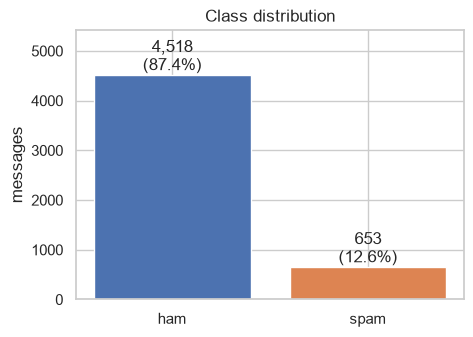

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = df["label"].value_counts()
ax.bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("messages"); ax.set_title("Class distribution"); ax.set_ylim(0, counts.max() * 1.2)
plt.show()

The dataset is **imbalanced** (~12–13 % spam). Accuracy alone would be misleading — a model that always answers *ham* would reach ~87 % — so precision, recall, F1 and ROC-AUC are reported.

### 3.2 Message length

label             ham   spam
n_chars count  4518.0  653.0
        mean     70.9  137.7
        std      56.6   29.8
        min       2.0   13.0
        25%      34.0  132.0
        50%      53.0  148.0
        75%      91.0  157.0
        max     910.0  223.0
n_words count  4518.0  653.0
        mean     14.2   23.7
        std      11.2    5.9
        min       1.0    2.0
        25%       7.0   22.0
        50%      11.0   25.0
        75%      19.0   28.0
        max     171.0   35.0

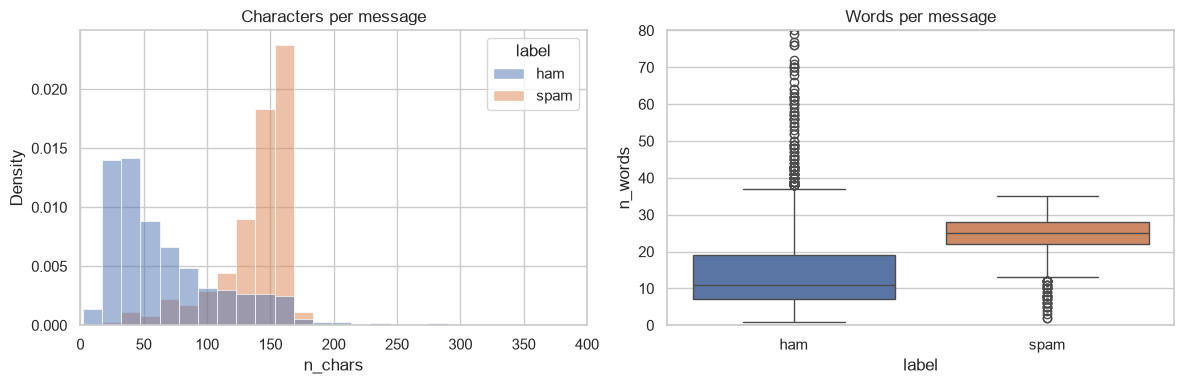

In [6]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
display(df.groupby("label")[["n_chars", "n_words"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="n_chars", hue="label", bins=60, palette=PALETTE, stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_xlim(0, 400); axes[0].set_title("Characters per message")
sns.boxplot(data=df, x="label", y="n_words", palette=PALETTE, ax=axes[1])
axes[1].set_ylim(0, 80); axes[1].set_title("Words per message")
plt.tight_layout(); plt.show()

Spam messages are clearly **longer** (median ~150 characters, close to the 160-character SMS limit) while ham messages are short and conversational. Practically every message fits in the model's 128-token window, so truncation barely affects the data.

In [7]:
tok_check = AutoTokenizer.from_pretrained("Goodmotion/spam-mail-classifier")
n_tokens = df["text"].apply(lambda t: len(tok_check(t)["input_ids"]))
print(f"Messages longer than 128 tokens: {(n_tokens > 128).sum()} ({(n_tokens > 128).mean():.2%})")

Messages longer than 128 tokens: 10 (0.19%)


### 3.3 Typical spam signals

label,ham,spam
has_url,0.3%,16.1%
has_phone_number,0.1%,76.7%
has_currency,0.7%,36.6%
has_free/win,1.7%,37.7%
uppercase_ratio>0.3,2.5%,2.9%


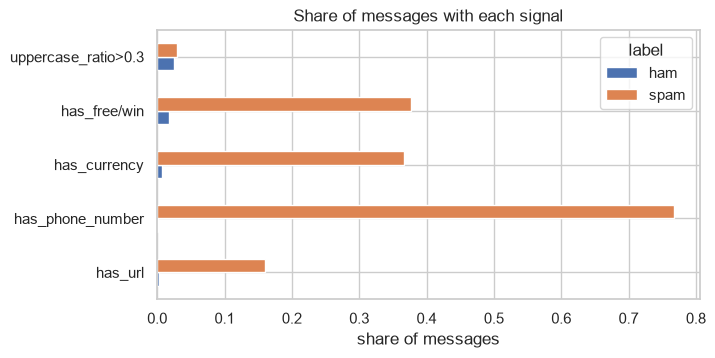

In [8]:
features = pd.DataFrame({
    "label": df["label"],
    "has_url": df["text"].str.contains(r"http|www\.|\.com", case=False, regex=True),
    "has_phone_number": df["text"].str.contains(r"\d{5,}", regex=True),
    "has_currency": df["text"].str.contains(r"[£$€]|\bcash\b|\bprize\b", case=False, regex=True),
    "has_free/win": df["text"].str.contains(r"\bfree\b|\bwin\b|\bwon\b|\bwinner\b", case=False, regex=True),
    "uppercase_ratio>0.3": df["text"].apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1) > 0.3),
})
signals = features.groupby("label").mean().T
display(signals.style.format("{:.1%}").background_gradient(axis=1, cmap="Oranges"))
signals.plot.barh(color=[PALETTE["ham"], PALETTE["spam"]], figsize=(7, 3.5),
                  title="Share of messages with each signal")
plt.xlabel("share of messages"); plt.show()

Long numbers (premium phone numbers / short codes), money words, *free/win* vocabulary and URLs are far more frequent in spam. These are the patterns a model is expected to capture.

### 3.4 Most frequent words

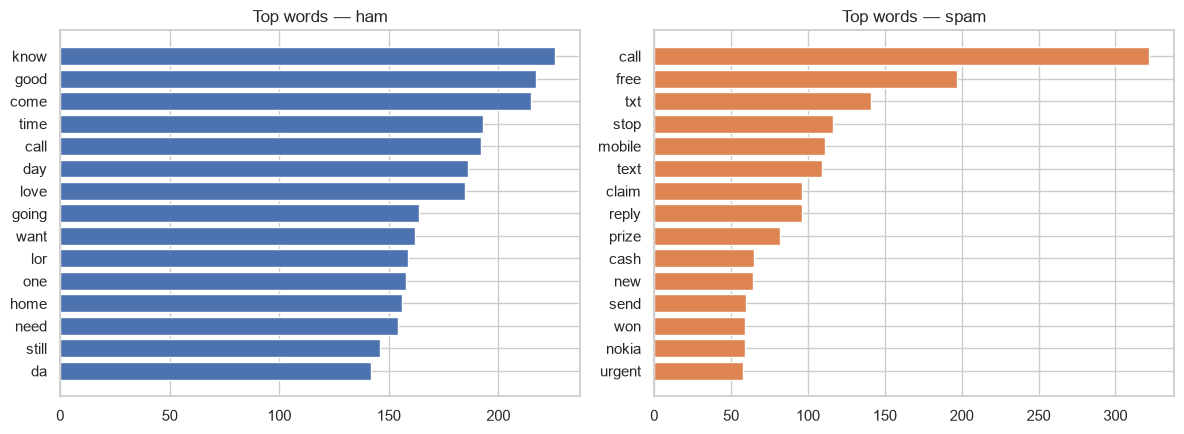

In [9]:
STOP = set(STOPWORDS) | {"u", "ur", "im", "ok", "will", "now", "get", "go", "got", "lt", "gt", "&lt;#&gt;"}

def top_words(texts, n=15):
    words = re.findall(r"[a-z']{2,}", " ".join(texts).lower())
    return Counter(w for w in words if w not in STOP).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, lab in zip(axes, ["ham", "spam"]):
    w, c = zip(*top_words(df.loc[df["label"] == lab, "text"]))
    ax.barh(w[::-1], c[::-1], color=PALETTE[lab]); ax.set_title(f"Top words — {lab}")
plt.tight_layout(); plt.show()

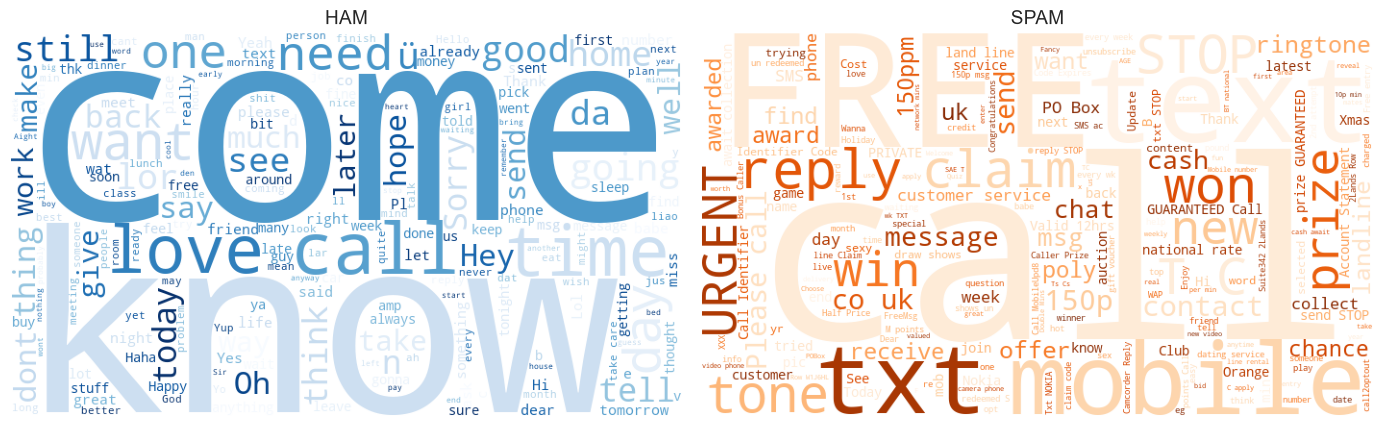

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, cmap in zip(axes, ["ham", "spam"], ["Blues", "Oranges"]):
    wc = WordCloud(width=700, height=400, background_color="white", stopwords=STOP,
                   colormap=cmap, random_state=42).generate(" ".join(df.loc[df["label"] == lab, "text"]))
    ax.imshow(wc); ax.axis("off"); ax.set_title(lab.upper(), fontsize=14)
plt.tight_layout(); plt.show()

Spam vocabulary is dominated by commercial calls to action (*call, free, txt, claim, prize, mobile, reply, stop*), while ham contains everyday conversation (*love, home, day, time, know*).

## 4. Preprocessing
Transformers work best on **raw text**: the model's own SentencePiece tokenizer handles casing, punctuation and sub-words, so no stemming, stop-word removal or lower-casing is applied. Preprocessing is limited to:

* removing duplicates and stripping whitespace (done above),
* mapping labels to integers aligned with the model output: `ham → 0 (NOSPAM)`, `spam → 1 (SPAM)`,
* tokenization with `truncation=True, max_length=128` (same settings used to train the model).

## 5. Inference with the pre-trained model

In [11]:
MODEL_NAME = "Goodmotion/spam-mail-classifier"
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device).eval()
print("device:", device, "| parameters:", f"{sum(p.numel() for p in model.parameters())/1e6:.1f} M")
print(model.config.id2label)

device: cpu | parameters: 117.7 M
{0: 'LABEL_0', 1: 'LABEL_1'}


In [12]:
@torch.inference_mode()
def predict_proba(texts, batch_size=64):
    probs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=128, return_tensors="pt").to(device)
        probs.append(torch.softmax(model(**enc).logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

t0 = time.time()
df["p_spam"] = predict_proba(df["text"].tolist())
elapsed = time.time() - t0
print(f"{len(df):,} messages in {elapsed:.1f} s ({len(df)/elapsed:.0f} msg/s)")
df[["label", "p_spam", "text"]].head()

5,171 messages in 283.9 s (18 msg/s)


,label,p_spam,text
0,ham,0.997699,"Go until jurong point, crazy.. Available only ..."
1,ham,0.010495,Ok lar... Joking wif u oni...
2,spam,0.001263,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,0.998495,U dun say so early hor... U c already then say...
4,ham,0.982562,"Nah I don't think he goes to usf, he lives aro..."


## 6. Evaluation

### 6.1 Default threshold (0.5)

In [13]:
def evaluate(y_true, p, thr):
    y_pred = (p >= thr).astype(int)
    return {
        "threshold": float(thr),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }

y, p = df["y"].values, df["p_spam"].values
m05 = evaluate(y, p, 0.5)
print(classification_report(y, (p >= 0.5).astype(int), target_names=["ham", "spam"], digits=3))
roc_auc, ap = roc_auc_score(y, p), average_precision_score(y, p)
print(f"ROC-AUC = {roc_auc:.3f} | Average precision (PR-AUC) = {ap:.3f}")

              precision    recall  f1-score   support

         ham      0.910     0.382     0.539      4518
        spam      0.148     0.740     0.246       653

    accuracy                          0.428      5171
   macro avg      0.529     0.561     0.392      5171
weighted avg      0.814     0.428     0.502      5171

ROC-AUC = 0.614 | Average precision (PR-AUC) = 0.175


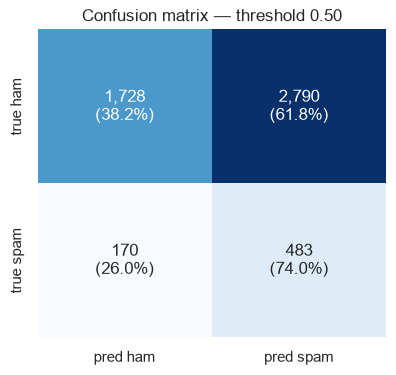

In [14]:
def plot_cm(cm, title, ax):
    cm = np.array(cm)
    sns.heatmap(cm, annot=np.array([[f"{v:,}\n({v/cm[i].sum():.1%})" for v in row] for i, row in enumerate(cm)]),
                fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred ham", "pred spam"], yticklabels=["true ham", "true spam"])
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(4.5, 4))
plot_cm(m05["confusion_matrix"], "Confusion matrix — threshold 0.50", ax); plt.show()

### 6.2 Score distribution, ROC and Precision-Recall curves

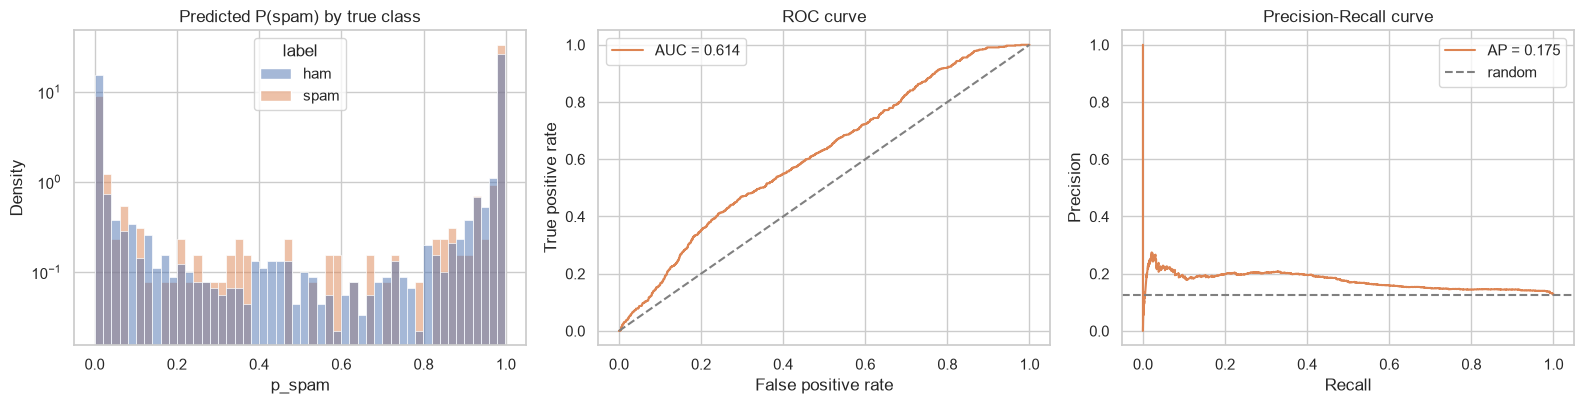

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(data=df, x="p_spam", hue="label", bins=50, palette=PALETTE, stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Predicted P(spam) by true class"); axes[0].set_yscale("log")

fpr, tpr, _ = roc_curve(y, p)
axes[1].plot(fpr, tpr, color=PALETTE["spam"], label=f"AUC = {roc_auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_title("ROC curve")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()

prec, rec, thr_pr = precision_recall_curve(y, p)
axes[2].plot(rec, prec, color=PALETTE["spam"], label=f"AP = {ap:.3f}")
axes[2].axhline(y.mean(), ls="--", color="grey", label="random")
axes[2].set_title("Precision-Recall curve"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].legend(); plt.tight_layout(); plt.show()

### 6.3 Decision-threshold tuning
The model was trained on a different domain (e-mail subjects), so its probabilities may not be calibrated for SMS. We search the threshold that maximises F1. *Note:* because the threshold is chosen on the same data used for evaluation, the tuned result is slightly optimistic; it is reported separately from the 0.5 baseline.

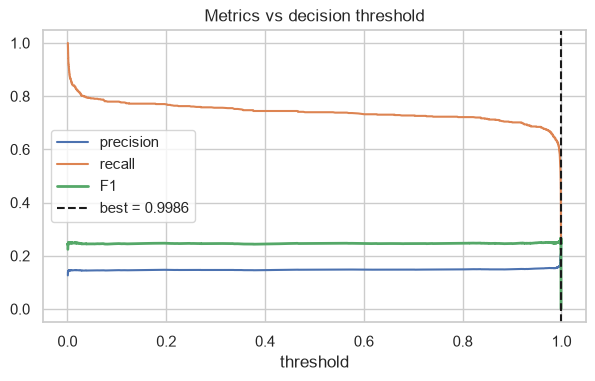

,threshold,accuracy,precision,recall,f1
threshold 0.50,0.500,0.428,0.148,0.740,0.246
best-F1 0.9986,0.999,0.674,0.186,0.469,0.266


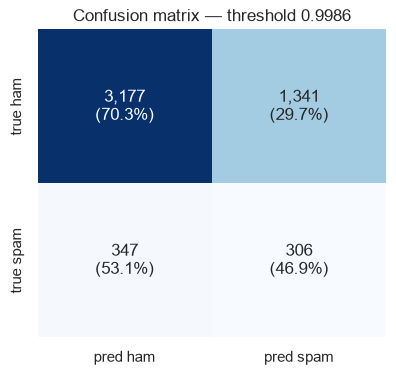

In [16]:
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_thr = float(thr_pr[np.argmax(f1s)])
m_best = evaluate(y, p, best_thr)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thr_pr, prec[:-1], label="precision"); ax.plot(thr_pr, rec[:-1], label="recall")
ax.plot(thr_pr, f1s, label="F1", lw=2); ax.axvline(best_thr, ls="--", color="k", label=f"best = {best_thr:.4f}")
ax.set_xlabel("threshold"); ax.set_title("Metrics vs decision threshold"); ax.legend(); plt.show()

summary = pd.DataFrame([m05, m_best], index=["threshold 0.50", f"best-F1 {best_thr:.4f}"]).drop(columns="confusion_matrix")
display(summary.round(3))
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_cm(m_best["confusion_matrix"], f"Confusion matrix — threshold {best_thr:.4f}", ax); plt.show()

## 7. Error analysis

In [17]:
thr = best_thr
df["pred"] = (df["p_spam"] >= thr).astype(int)
fp = df[(df["y"] == 0) & (df["pred"] == 1)].sort_values("p_spam", ascending=False)
fn = df[(df["y"] == 1) & (df["pred"] == 0)].sort_values("p_spam")
print(f"False positives (ham flagged as spam): {len(fp)} | False negatives (missed spam): {len(fn)}")
pd.set_option("display.max_colwidth", 140)
print("\nTop false positives:"); display(fp[["p_spam", "text"]].head(8))
print("Top false negatives:"); display(fn[["p_spam", "text"]].head(8))

False positives (ham flagged as spam): 1341 | False negatives (missed spam): 347

Top false positives:


,p_spam,text
3477,0.999164,Great! I shoot big loads so get ready!
2869,0.999163,I thank you so much for all you do with selflessness. I love you plenty.
2809,0.999162,Hey now am free you can call me.
212,0.999162,Sounds great! Are you home now?
4783,0.999162,That sucks. I'll go over so u can do my hair. You'll do it free right?
3698,0.999161,Sos! Any amount i can get pls.
1390,0.999161,You intrepid duo you! Have a great time and see you both soon.
487,0.999161,Are you free now?can i call now?


Top false negatives:


,p_spam,text
935,0.000872,Filthy stories and GIRLS waiting for your
701,0.000896,08714712388 between 10am-7pm Cost 10p
4773,0.000939,PRIVATE! Your 2003 Account Statement for 078
2180,0.000939,88066 FROM 88066 LOST 3POUND HELP
2642,0.000953,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...
3743,0.000984,ringtoneking 84484
3858,0.001073,"HOT LIVE FANTASIES call now 08707500020 Just 20p per min NTT Ltd, PO Box 1327 Croydon CR9 5WB 0870 is a national rate call"
3416,0.001076,8007 25p 4 Alfie Moon's Children in Need song on ur mob. Tell ur m8s. Txt TONE CHARITY to 8007 for nokias or POLY CHARITY for polys :zed...


In [18]:
df["len_bin"] = pd.cut(df["n_chars"], [0, 40, 80, 120, 160, 1000], labels=["≤40", "41-80", "81-120", "121-160", ">160"])
by_len = df.groupby("len_bin", observed=True).apply(
    lambda g: pd.Series({"messages": len(g), "spam_share": g["y"].mean(),
                         "accuracy": accuracy_score(g["y"], g["pred"]),
                         "recall_spam": recall_score(g["y"], g["pred"], zero_division=np.nan)}))
by_len.round(3)

,messages,spam_share,accuracy,recall_spam
len_bin,,,,
≤40,1619.0,0.006,0.824,0.111
41-80,1573.0,0.024,0.650,0.342
81-120,716.0,0.108,0.601,0.416
121-160,1021.0,0.468,0.564,0.496
>160,242.0,0.211,0.500,0.451


### 7.1 Manual tests (English and Spanish)

In [19]:
samples = [
    "WINNER!! You have been selected to receive a £900 prize reward! To claim call 09061701461.",
    "URGENT! Your mobile number has won a £2000 bonus. Call 09066350750 from a landline now",
    "FREE entry into our weekly competition, just text WIN to 80086 now!",
    "Hey, are we still meeting for lunch tomorrow at 1pm?",
    "I'll be home late tonight, don't wait for me for dinner",
    "¡Felicidades! Ganaste un iPhone gratis. Haz clic aquí para reclamarlo hoy.",
    "Tu cuenta bancaria fue bloqueada, ingresa a este enlace para verificar tus datos",
    "Hola mamá, ya llegué a la casa. Mañana te llamo.",
    "Reunión del proyecto movida al jueves a las 3 pm",
]
probs = predict_proba(samples)
pd.DataFrame({"text": samples, "p_spam": probs.round(3),
              "prediction": np.where(probs >= best_thr, "spam", "ham")})

,text,p_spam,prediction
0,WINNER!! You have been selected to receive a £900 prize reward! To claim call 09061701461.,0.999,spam
1,URGENT! Your mobile number has won a £2000 bonus. Call 09066350750 from a landline now,0.999,spam
2,"FREE entry into our weekly competition, just text WIN to 80086 now!",0.999,spam
3,"Hey, are we still meeting for lunch tomorrow at 1pm?",0.001,ham
4,"I'll be home late tonight, don't wait for me for dinner",0.001,ham
5,¡Felicidades! Ganaste un iPhone gratis. Haz clic aquí para reclamarlo hoy.,0.999,spam
6,"Tu cuenta bancaria fue bloqueada, ingresa a este enlace para verificar tus datos",0.999,spam
7,"Hola mamá, ya llegué a la casa. Mañana te llamo.",0.003,ham
8,Reunión del proyecto movida al jueves a las 3 pm,0.001,ham


## 8. Conclusions

In [20]:
print(f"Unique messages evaluated: {len(df):,}  (spam {df.y.sum():,} / ham {(1-df.y).sum():,})")
print(f"ROC-AUC: {roc_auc:.3f} | PR-AUC: {ap:.3f}")
for name, m in [("threshold 0.50", m05), (f"threshold {best_thr:.4f}", m_best)]:
    print(f"{name:>16}: acc={m['accuracy']:.3f} prec={m['precision']:.3f} rec={m['recall']:.3f} f1={m['f1']:.3f}")

Unique messages evaluated: 5,171  (spam 653 / ham 4,518)
ROC-AUC: 0.614 | PR-AUC: 0.175
  threshold 0.50: acc=0.428 prec=0.148 rec=0.740 f1=0.246
threshold 0.9986: acc=0.674 prec=0.186 rec=0.469 f1=0.266


**Findings**

1. **Data.** 5,574 SMS (5,171 after removing 403 duplicates), imbalanced: 87.4 % ham / 12.6 % spam. Spam is longer (median 148 vs 53 characters) and full of premium phone numbers, money words and *free / win / claim / txt* vocabulary. Only 0.2 % of messages exceed the 128-token window.
2. **Out-of-the-box transfer to SMS is weak.** Used without re-training, `Goodmotion/spam-mail-classifier` reaches **ROC-AUC ≈ 0.61** and **PR-AUC ≈ 0.18** on the SMS corpus. At the default 0.5 threshold it recovers ~74 % of the spam but also flags ~62 % of legitimate messages, so accuracy (~43 %) is below the trivial "always ham" baseline (~87 %).
3. **Threshold tuning barely helps** (best F1 ≈ 0.27 vs 0.25), because the problem is the *ranking*, not the cut-off: the model is over-confident (probabilities cluster at 0 and 1) on text it was not trained for.
4. **Why — domain shift.** The model was fine-tuned on **e-mail subjects**. SMS ham is informal, short and full of slang/abbreviations (*u, ur, 2, 4, lor, wat*), and the error analysis shows short friendly messages (*"Sounds great! Are you home now?"*, *"Are you free now? can i call now?"*) marked as spam, while classic SMS spam built on short codes and premium numbers (*"ringtoneking 84484"*, *"08714712388 between 10am-7pm Cost 10p"*) is missed.
5. **Where it works.** On clean, well-formed sentences — including **Spanish**, thanks to the multilingual backbone — the manual tests are classified correctly with high confidence, which is consistent with its e-mail-subject training domain.

**Recommendations / next steps**

* Fine-tune the same multilingual backbone on a train split of the SMS data (stratified, deduplicated) and evaluate on a held-out test split; a TF-IDF + logistic-regression baseline would be a useful reference.
* Calibrate probabilities (Platt / isotonic) on in-domain data before choosing a production threshold.
* In the web app the default threshold is kept at 0.5 (the tuned value ≈ 0.999 brings almost no gain) and the user can move it.

In [21]:
metrics = {
    "model": MODEL_NAME,
    "dataset": "UCI SMS Spam Collection (deduplicated)",
    "n_messages": int(len(df)), "n_spam": int(df["y"].sum()), "n_ham": int((1 - df["y"]).sum()),
    "roc_auc": float(roc_auc), "average_precision": float(ap),
    "recommended_threshold": round(best_thr, 4),
    "threshold_0_5": {k: (float(v) if not isinstance(v, list) else v) for k, v in m05.items()},
    "threshold_best": {k: (float(v) if not isinstance(v, list) else v) for k, v in m_best.items()},
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Saved", METRICS_PATH)

Saved C:\Users\Pedro Jojoa\Desktop\Detección de SPAM\app\metrics.json
